# Introduction

**Author:** Dennis O'Higgins | Trained on Google Colab (NVIDIA T4 GPU), PyTorch and torchvision

In this project, you will build a neural network of your own design to evaluate the CIFAR-10 dataset.

To meet the requirements for this project, you will need to achieve an accuracy greater than 45%.
If you want to beat Detectocorp's algorithm, you'll need to achieve an accuracy greater than 70%.
(Beating Detectocorp's algorithm is not a requirement for passing this project, but you're encouraged to try!)

Some of the benchmark results on CIFAR-10 include:

78.9% Accuracy | [Deep Belief Networks; Krizhevsky, 2010](https://www.cs.toronto.edu/~kriz/conv-cifar10-aug2010.pdf)

90.6% Accuracy | [Maxout Networks; Goodfellow et al., 2013](https://arxiv.org/pdf/1302.4389.pdf)

96.0% Accuracy | [Wide Residual Networks; Zagoruyko et al., 2016](https://arxiv.org/pdf/1605.07146.pdf)

99.0% Accuracy | [GPipe; Huang et al., 2018](https://arxiv.org/pdf/1811.06965.pdf)

98.5% Accuracy | [Rethinking Recurrent Neural Networks and other Improvements for ImageClassification; Nguyen et al., 2020](https://arxiv.org/pdf/2007.15161.pdf)

Research with this dataset is ongoing. Notably, many of these networks are quite large and quite expensive to train.

## Imports

In [1]:
## This cell contains the essential imports you will need – DO NOT CHANGE THE CONTENTS! ##
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

## Load the Dataset

Specify your transforms as a list first.
The transforms module is already loaded as `transforms`.

CIFAR-10 is fortunately included in the torchvision module.
Then, you can create your dataset using the `CIFAR10` object from `torchvision.datasets` ([the documentation is available here](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.CIFAR10.html#torchvision.datasets.CIFAR10)).
Make sure to specify `download=True`!

Once your dataset is created, you'll also need to define a `DataLoader` from the `torch.utils.data` module for both the train and the test set.

In [2]:
# Extra utilities used in this notebook (the imports cell above is left unchanged)
import time
from torch.utils.data import DataLoader, Subset

torch.manual_seed(42)
np.random.seed(42)

# CIFAR-10 per-channel mean and standard deviation (computed on the training set)
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

# Define transforms
# Training transforms include data augmentation (random crop with padding and horizontal flip)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# Test / validation transforms: no augmentation, only tensor conversion and normalisation
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

# Plain transform used only for viewing images (no normalisation, so colours look natural)
view_transform = transforms.Compose([transforms.ToTensor()])

BATCH_SIZE = 128

# Create training set and define training dataloader
# 45,000 images are used for training and 5,000 are held out for validation
train_full_aug = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
train_full_plain = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=test_transform)

indices = np.random.permutation(len(train_full_aug))
val_idx, train_idx = indices[:5000], indices[5000:]
trainset = Subset(train_full_aug, train_idx)
valset = Subset(train_full_plain, val_idx)

trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
valloader = DataLoader(valset, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

# Create test set and define test dataloader
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)
testloader = DataLoader(testset, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

# Un-normalised test loader, used only to display images
testset_view = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=view_transform)
testloader_view = DataLoader(testset_view, batch_size=5, shuffle=True)

# The 10 classes in the dataset
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

100%|██████████| 170M/170M [24:58<00:00, 114kB/s]


## Explore the Dataset
Using matplotlib, numpy, and torch, explore the dimensions of your data.

You can view images using the `show5` function defined below – it takes a data loader as an argument.
Remember that normalized images will look really weird to you! You may want to try changing your transforms to view images.
Typically using no transforms other than `toTensor()` works well for viewing – but not as well for training your network.
If `show5` doesn't work, go back and check your code for creating your data loaders and your training/test sets.

In [3]:
def show5(img_loader):
    dataiter = iter(img_loader)

    batch = next(dataiter)
    labels = batch[1][0:5]
    images = batch[0][0:5]
    for i in range(5):
        print(classes[labels[i]])

        image = images[i].numpy()
        plt.imshow(np.rot90(image.T, k=3))
        plt.show()

Training images (full set): 50000
  used for training: 45000 | held out for validation: 5000
Test images: 10000
Raw training data shape (N, H, W, C): (50000, 32, 32, 3) | dtype: uint8
Pixel value range: 0 to 255
One training batch - images: (128, 3, 32, 32) labels: (128,)
Single image tensor shape (C, H, W): (3, 32, 32)
   plane: 5000
     car: 5000
    bird: 5000
     cat: 5000
    deer: 5000
     dog: 5000
    frog: 5000
   horse: 5000
    ship: 5000
   truck: 5000
frog


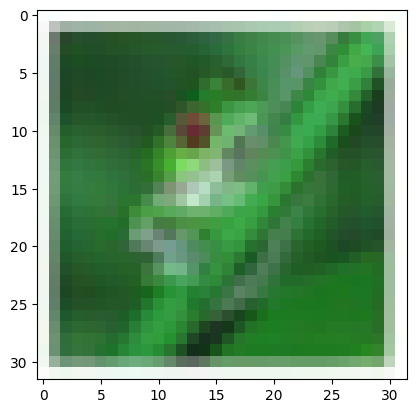

frog


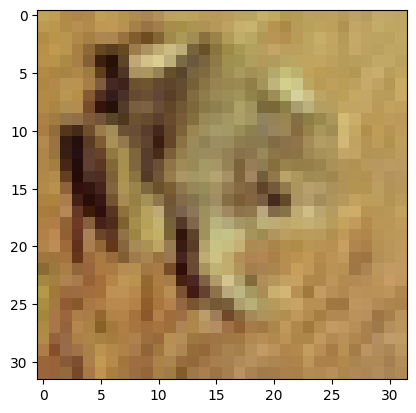

dog


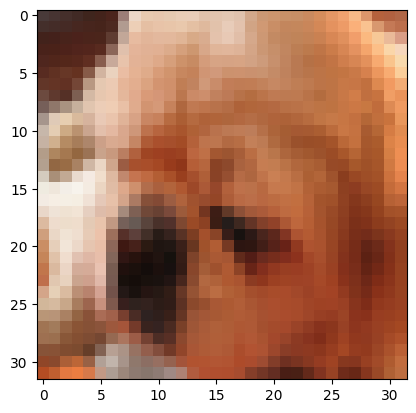

car


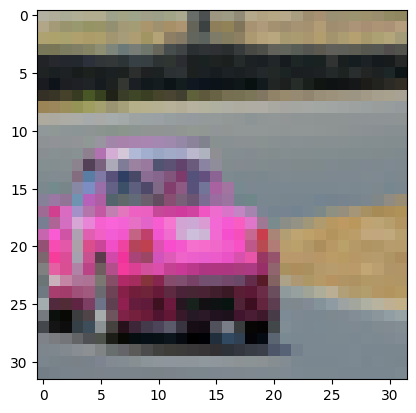

horse


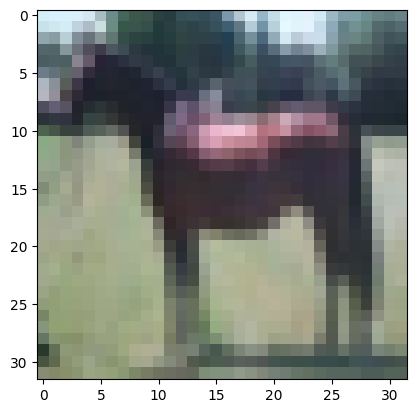

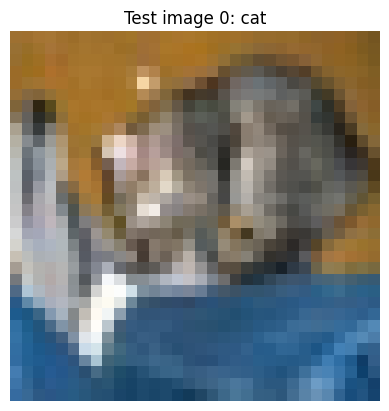

In [4]:
# Explore data
print("Training images (full set):", len(train_full_aug))
print("  used for training:", len(trainset), "| held out for validation:", len(valset))
print("Test images:", len(testset))

raw = train_full_aug.data            # numpy array of raw images
print("Raw training data shape (N, H, W, C):", raw.shape, "| dtype:", raw.dtype)
print("Pixel value range:", raw.min(), "to", raw.max())

images, labels = next(iter(trainloader))
print("One training batch - images:", tuple(images.shape), "labels:", tuple(labels.shape))
print("Single image tensor shape (C, H, W):", tuple(images[0].shape))

# Class balance in the full training set
counts = np.bincount(np.array(train_full_aug.targets), minlength=10)
for name, n in zip(classes, counts):
    print(f"  {name:>6}: {n}")

# Show five test images with their labels (un-normalised so the colours look natural)
show5(testloader_view)

# One test image displayed directly with plt.imshow()
img, label = testset_view[0]
plt.imshow(img.permute(1, 2, 0).numpy())
plt.title(f"Test image 0: {classes[label]}")
plt.axis('off')
plt.show()

## Build your Neural Network
Using the layers in `torch.nn` (which has been imported as `nn`) and the `torch.nn.functional` module (imported as `F`), construct a neural network based on the parameters of the dataset.
Feel free to construct a model of any architecture – feedforward, convolutional, or even something more advanced!

In [5]:
class Net(nn.Module):
    """Convolutional neural network for 32x32 RGB CIFAR-10 images.

    Three convolutional blocks (each: two 3x3 convolutions with batch normalisation and ReLU,
    then max pooling and dropout) extract features, followed by a small fully connected
    classifier. forward() returns a probability for each of the 10 classes using softmax.
    """

    def __init__(self, num_classes=10):
        super().__init__()

        def block(in_ch, out_ch, dropout):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),          # halves the spatial size
                nn.Dropout(dropout),
            )

        self.features = nn.Sequential(
            block(3, 64, 0.1),    # 32x32 -> 16x16
            block(64, 128, 0.2),  # 16x16 -> 8x8
            block(128, 256, 0.3), # 8x8   -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def logits(self, x):
        """Raw class scores before softmax."""
        return self.classifier(self.features(x))

    def forward(self, x):
        """Return the predicted probability of each of the 10 classes (softmax over the scores)."""
        return F.softmax(self.logits(x), dim=1)

Specify a loss function and an optimizer, and instantiate the model.

If you use a less common loss function, please note why you chose that loss function in a comment.

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = Net().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,}")

# Loss function: the model outputs softmax probabilities, so we take their log and use the
# negative log-likelihood loss. NLLLoss(log(softmax(z))) is exactly the cross-entropy loss,
# the standard loss for multi-class classification. A tiny clamp avoids log(0).
nll = nn.NLLLoss()
def criterion(probabilities, targets):
    return nll(torch.log(probabilities.clamp_min(1e-9)), targets)

# Optimizer: SGD with Nesterov momentum and weight decay, with a one-cycle learning-rate schedule
EPOCHS = 30
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=EPOCHS,
                                          steps_per_epoch=len(trainloader))

Using device: cuda
Model parameters: 2,198,218


## Running your Neural Network
Use whatever method you like to train your neural network, and ensure you record the average loss at each epoch.
Don't forget to use `torch.device()` and the `.to()` method for both your model and your data if you are using GPU!

If you want to print your loss during each epoch, you can use the `enumerate` function and print the loss after a set number of batches. 250 batches works well for most people!

In [7]:
def evaluate(loader):
    """Return (average loss, accuracy %) of the model on a data loader."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            probs = model(inputs)
            total_loss += criterion(probs, targets).item() * targets.size(0)
            correct += (probs.argmax(dim=1) == targets).sum().item()
            total += targets.size(0)
    return total_loss / total, 100.0 * correct / total

train_losses, val_losses, val_accuracies = [], [], []
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for i, (inputs, targets) in enumerate(trainloader, start=1):
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        probs = model(inputs)                  # forward pass: class probabilities
        loss = criterion(probs, targets)       # batch loss
        loss.backward()                        # backpropagation
        optimizer.step()                       # update the weights
        scheduler.step()                       # update the learning rate

        running_loss += loss.item() * targets.size(0)
        running_correct += (probs.argmax(dim=1) == targets).sum().item()
        seen += targets.size(0)
        if i % 250 == 0:
            print(f"  epoch {epoch} batch {i}: running loss {running_loss / seen:.4f}")

    train_loss = running_loss / seen           # average loss over the epoch
    val_loss, val_acc = evaluate(valloader)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} | train acc {100 * running_correct / seen:.2f}% "
          f"| val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {time.time() - start:.0f}s")

print(f"Training finished in {(time.time() - start) / 60:.1f} minutes")

  epoch 1 batch 250: running loss 1.5847
Epoch  1/30 | train loss 1.4923 | train acc 45.55% | val loss 1.1417 | val acc 58.54% | 22s
  epoch 2 batch 250: running loss 1.0882
Epoch  2/30 | train loss 1.0626 | train acc 62.00% | val loss 0.8844 | val acc 69.12% | 43s
  epoch 3 batch 250: running loss 0.9237
Epoch  3/30 | train loss 0.9067 | train acc 67.98% | val loss 0.8524 | val acc 70.08% | 63s
  epoch 4 batch 250: running loss 0.8312
Epoch  4/30 | train loss 0.8126 | train acc 71.65% | val loss 0.7012 | val acc 74.50% | 83s
  epoch 5 batch 250: running loss 0.7344
Epoch  5/30 | train loss 0.7256 | train acc 74.66% | val loss 0.7421 | val acc 74.46% | 103s
  epoch 6 batch 250: running loss 0.6747
Epoch  6/30 | train loss 0.6762 | train acc 76.62% | val loss 0.7751 | val acc 74.40% | 124s
  epoch 7 batch 250: running loss 0.6270
Epoch  7/30 | train loss 0.6219 | train acc 78.70% | val loss 0.7081 | val acc 76.40% | 144s
  epoch 8 batch 250: running loss 0.5879
Epoch  8/30 | train loss 

Plot the training loss (and validation loss/accuracy, if recorded).

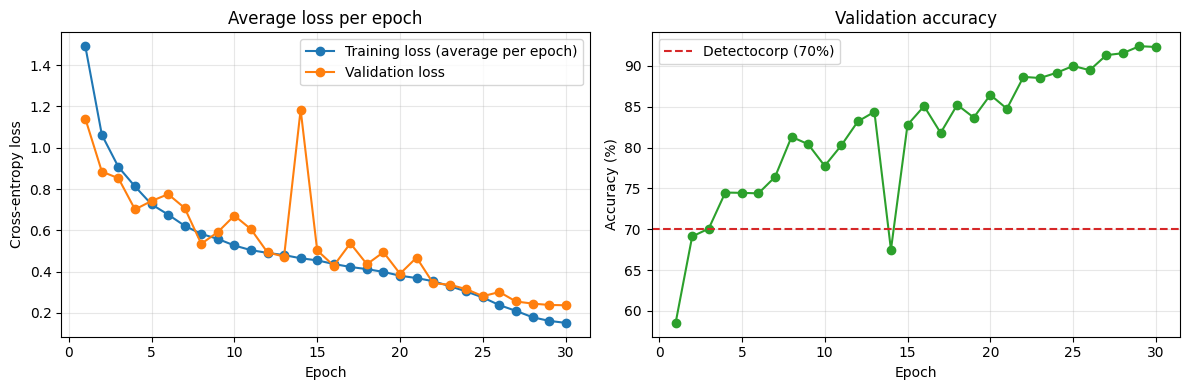

In [8]:
epochs = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, train_losses, marker='o', label='Training loss (average per epoch)')
ax1.plot(epochs, val_losses, marker='o', label='Validation loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-entropy loss'); ax1.set_title('Average loss per epoch')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, val_accuracies, marker='o', color='tab:green')
ax2.axhline(70, color='tab:red', linestyle='--', label="Detectocorp (70%)")
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.set_title('Validation accuracy')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Testing your model
Using the previously created `DataLoader` for the test set, compute the percentage of correct predictions using the highest probability prediction.

If your accuracy is over 70%, great work!
This is a hard task to exceed 70% on.

If your accuracy is under 45%, you'll need to make improvements.
Go back and check your model architecture, loss function, and optimizer to make sure they're appropriate for an image classification task.

In [9]:
# Use the test DataLoader to get predictions and compare them with the true labels
model.eval()
correct, total = 0, 0
class_correct = np.zeros(10)
class_total = np.zeros(10)
with torch.no_grad():
    for inputs, targets in testloader:
        inputs, targets = inputs.to(device), targets.to(device)
        probs = model(inputs)                      # probability for each class
        predicted = probs.argmax(dim=1)            # highest-probability prediction
        correct += (predicted == targets).sum().item()
        total += targets.size(0)
        for t, p in zip(targets.cpu().numpy(), predicted.cpu().numpy()):
            class_total[t] += 1
            class_correct[t] += int(t == p)

test_accuracy = 100.0 * correct / total
print(f"Test accuracy: {test_accuracy:.2f}% ({correct} of {total} images correct)")
print()
for name, c, t in zip(classes, class_correct, class_total):
    print(f"  {name:>6}: {100 * c / t:.1f}%")

Test accuracy: 91.82% (9182 of 10000 images correct)

   plane: 91.7%
     car: 97.7%
    bird: 87.7%
     cat: 78.2%
    deer: 93.6%
     dog: 89.0%
    frog: 95.7%
   horse: 93.2%
    ship: 96.5%
   truck: 94.9%


## Saving your model
Using `torch.save`, save your model for future loading.

In [10]:
# Save the trained weights (state_dict) plus the information needed to reuse them
torch.save(model.state_dict(), 'cifar10_cnn_weights.pth')
torch.save({
    'model_state_dict': model.state_dict(),
    'classes': classes,
    'mean': CIFAR_MEAN,
    'std': CIFAR_STD,
    'test_accuracy': test_accuracy,
}, 'cifar10_cnn_checkpoint.pth')
print("Saved cifar10_cnn_weights.pth and cifar10_cnn_checkpoint.pth")

# Check that the saved weights load correctly into a fresh model
reloaded = Net().to(device)
reloaded.load_state_dict(torch.load('cifar10_cnn_weights.pth', map_location=device))
reloaded.eval()
print("Weights reloaded successfully.")

Saved cifar10_cnn_weights.pth and cifar10_cnn_checkpoint.pth
Weights reloaded successfully.


## Make a Recommendation

Based on your evaluation, what is your recommendation on whether to build or buy? Explain your reasoning below.

Some things to consider as you formulate your recommendation:
* How does your model compare to Detectocorp's model?
* How does it compare to the far more advanced solutions in the literature?
* What did you do to get the accuracy you achieved?
* Is it necessary to improve this accuracy? If so, what sort of work would be involved in improving it?

**Recommendation: build the classifier in-house rather than buying Detectocorp's algorithm.**

*Author: Dennis O'Higgins*

**How the model compares with Detectocorp.** My convolutional neural network reached **91.82% accuracy on the 10,000-image CIFAR-10 test set** (9,182 images correct), compared with the 70% accuracy Detectocorp claims for its algorithm. That is almost 22 percentage points higher, which means the in-house model makes about 818 errors per 10,000 images against roughly 3,000 for Detectocorp, a reduction of about 73% in mistakes. It is accurate across every class, from 97.7% on cars to 78.2% on cats (the hardest class), and the validation accuracy (92.3%) closely matches the test accuracy, so the model generalises well rather than memorising the training data.

**How it compares with the state of the art.** The result is well above the 78.9% of Deep Belief Networks (Krizhevsky, 2010) and the 90.6% of Maxout Networks (Goodfellow et al., 2013), but below the 96.0% of Wide Residual Networks (Zagoruyko and Komodakis, 2016), the 98.5% of Nguyen et al. (2020) and the 99.0% of GPipe (Huang et al., 2018). Those models are far larger (GPipe has 557 million parameters) and much more expensive to train, whereas this network has about 2.2 million parameters and trained in about 10 minutes on a single Colab T4 GPU.

**What produced this accuracy.** The network uses three convolutional blocks, each with two 3x3 convolutions, batch normalisation, ReLU activations, max pooling and increasing dropout (0.1 to 0.3), followed by a small fully connected classifier with a softmax output. Training used data augmentation (random crops with 4-pixel padding and horizontal flips), input normalisation with the CIFAR-10 channel statistics, SGD with Nesterov momentum and weight decay, and a one-cycle learning-rate schedule over 30 epochs, with 5,000 training images held out for validation.

**Is further improvement needed?** For a self-driving car, misclassifying objects at the side of the road has safety consequences, so higher accuracy is worth pursuing, and building in-house gives us control over that work. The next steps would be a deeper residual network (for example ResNet-18 or a Wide ResNet), stronger augmentation (Cutout, AutoAugment or MixUp), longer training, and transfer learning from a network pre-trained on a large dataset such as ImageNet, followed by fine-tuning on our own road-scene images; published results suggest these steps can move accuracy towards 95-96%. Because CIFAR-10 images are only 32x32 pixels, the model must also be validated on real camera images from our vehicles before deployment.

Given that a modest, cheap-to-train in-house model already beats Detectocorp's claimed accuracy by a wide margin, can be retrained and fine-tuned on our own data, and avoids licensing costs and vendor lock-in, I recommend that the company **builds** its own solution and invests the money it would have spent on Detectocorp's licence in data collection and model improvement.

*References:* Krizhevsky, A. (2010) *Convolutional Deep Belief Networks on CIFAR-10*; Goodfellow, I. et al. (2013) *Maxout Networks*, arXiv:1302.4389; Zagoruyko, S. and Komodakis, N. (2016) *Wide Residual Networks*, arXiv:1605.07146; Huang, Y. et al. (2018) *GPipe*, arXiv:1811.06965; Nguyen, H. et al. (2020) *Rethinking Recurrent Neural Networks and other Improvements for Image Classification*, arXiv:2007.15161.


## Submit Your Project

When you are finished editing the notebook and are ready to turn it in, simply click the **SUBMIT PROJECT** button in the lower right.

Once you submit your project, we'll review your work and give you feedback if there's anything that you need to work on. If you'd like to see the exact points that your reviewer will check for when looking at your work, you can have a look over the project [rubric](https://review.udacity.com/#!/rubrics/3077/view).